# 01 - Verkenning en cleaning

Eerste kennismaking met de scoutingdata (seizoen 2025-2026) en een eerste, voorlopige cleaning voor de Lens Model-analyse (Peringa et al., 2025).

**Vertaling naar het Lens Model**

| Lens Model | In deze data |
|---|---|
| Rechter | scout (`scout_id`) |
| Oordeel $Y_s$ | `performance` (eventueel ook `potential`) |
| Cues $X_1 \dots X_k$ | sterrenvragen in `ratings.csv`, per categorie samengevat |
| Criterium $Y_e$ | **nog niet aanwezig in de data** |

**Werkwijze:** de cleaning verwijdert geen rapporten en overschrijft geen waarden. Twijfelgevallen krijgen een vlag, zodat we die keuzes later nog kunnen aanpassen. De open keuzes staan onderaan.

## 1. Inlezen

De export bevat persoonsgegevens. Namen en geboortedatums worden daarom niet ingelezen, zodat ze ook niet in de output van dit notebook belanden. Voor de analyse volstaan de id's en `player_age_at_match`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
CODEBOOK_DIR = DATA_DIR / "codebook"
CLEAN_DIR = DATA_DIR / "clean"

PERSONAL_COLS = {"scout_name", "player_name", "player_birthdate"}

# Voorlopige drempel: minimaal aandeel beantwoorde vragen om een rapport te gebruiken
MIN_SHARE_RATED = 0.5

pd.set_option("display.max_columns", None, "display.max_rows", 100, "display.max_colwidth", 90)

BLUE, ORANGE = "#2a78d6", "#eb6834"
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "xtick.bottom": False, "ytick.left": False,
    "legend.frameon": False,
})

In [2]:
reports = pd.read_csv(
    DATA_DIR / "reports.csv", encoding="utf-8-sig", usecols=lambda col: col not in PERSONAL_COLS
)
ratings = pd.read_csv(DATA_DIR / "ratings.csv", encoding="utf-8-sig")
questions = pd.read_csv(CODEBOOK_DIR / "questions.csv", encoding="utf-8-sig")
columns_doc = pd.read_csv(CODEBOOK_DIR / "columns.csv", encoding="utf-8-sig")
filters = pd.read_csv(CODEBOOK_DIR / "filters.csv", encoding="utf-8-sig")

print(f"reports:   {reports.shape}")
print(f"ratings:   {ratings.shape}")
print(f"questions: {questions.shape}")

reports:   (284, 52)
ratings:   (5403, 6)
questions: (235, 15)


## 2. Eerste blik

Elke kolom met type, ontbrekende waarden en de betekenis uit de codebook.

In [3]:
def overview(df, file_name):
    meaning = columns_doc.loc[columns_doc["file"] == file_name].set_index("column")["meaning"]
    return pd.DataFrame({
        "type": df.dtypes.astype(str),
        "ontbrekend": df.isna().sum(),
        "uniek": df.nunique(),
        "betekenis": meaning.reindex(df.columns),
    })


overview(reports, "reports.csv")

,type,ontbrekend,uniek,betekenis
report_id,int64,0,284,Platform id of the report (evaluations.id); key to ratings.csv.
season,str,0,1,Season of the match (1 July - 30 June).
mode,str,0,3,"How the scout watched: live, video, unknown (older reports)."
status,str,0,1,submitted or approved (drafts are not exported).
created_at,str,0,254,When the report was started (UTC).
submitted_at,str,0,254,When the report was submitted (UTC); empty on old reports.
days_match_to_submit,int64,0,42,Days between the match and submission.
assignment_id,int64,0,158,Scouting assignment the report belongs to (if any).
scout_id,int64,0,14,Platform id of the author (users.id).
scout_roles,str,10,2,"Author's platform role(s) today (coach, admin, ...)."


In [4]:
overview(ratings, "ratings.csv")

,type,ontbrekend,uniek,betekenis
report_id,int64,0,284,Key to reports.csv.
question_id,int64,0,235,Key to the codebook tab Questions (unique; question codes are NOT unique).
question_code,str,0,167,"Short code of the question (repeated across questionnaires, e.g. AFB1 in LB and RB)."
rating,float64,552,4,"1-4 stars (1 = poor, 4 = excellent); empty when N/A or not filled in."
is_na,int64,0,2,1 = the scout pressed N/A (could not be judged). Not a score.
is_missing,int64,0,2,1 = the question was left empty.


In [5]:
ratings.head()

,report_id,question_id,question_code,rating,is_na,is_missing
0,153,76,AFB1,3.0,0,0
1,153,77,AFB2,2.0,0,0
2,153,78,AFB3,NaN,1,0
3,153,79,AFB4,3.0,0,0
4,153,80,AFB5,2.0,0,0


In [6]:
# Vragen per vragenlijst en categorie: de cues verschillen per positie
questions.pivot_table(
    index="category_name", columns="questionnaire_position", values="question_id",
    aggfunc="count", fill_value=0,
)

questionnaire_position,CAM,CB,CDM,CF,CM,GK,LB,LW,RB,RW,ST
category_name,,,,,,,,,,,
1v1,0,0,0,0,0,2,0,0,0,0,0
2D,0,0,0,0,0,2,0,0,0,0,0
3D,0,0,0,0,0,2,0,0,0,0,0
Defensive,2,7,5,2,5,0,6,2,6,2,2
Defensive Transition,2,2,2,2,2,0,2,2,2,2,2
Distribution,0,0,0,0,0,2,0,0,0,0,0
Mental,3,3,3,3,3,0,3,3,3,3,3
Offensive,6,5,4,6,5,0,6,6,6,6,6
Offensive Transition,2,1,2,2,2,0,2,2,2,2,2


## 3. Integriteitschecks

Controles op zaken die volgens de codebook altijd moeten kloppen. Elke rij hoort **0** te geven.

In [7]:
per_report = ratings.groupby("report_id").agg(
    n_questions=("question_id", "size"),
    n_rated=("rating", "count"),
    n_na=("is_na", "sum"),
    n_missing=("is_missing", "sum"),
)
counts = reports.set_index("report_id")[per_report.columns].merge(
    per_report, left_index=True, right_index=True, suffixes=("", "_calc")
)

with_questionnaire = ratings.merge(reports[["report_id", "questionnaire_code"]], on="report_id").merge(
    questions[["question_id", "questionnaire_code"]], on="question_id", suffixes=("", "_question")
)

match_date = pd.to_datetime(reports["match_date"])
submitted_at = pd.to_datetime(reports["submitted_at"])
rating_empty = ratings["rating"].isna()
flagged_empty = (ratings["is_na"] == 1) | (ratings["is_missing"] == 1)

checks = {
    "report_id niet uniek": reports["report_id"].duplicated().sum(),
    "dubbele combinatie rapport x vraag": ratings.duplicated(["report_id", "question_id"]).sum(),
    "ratings zonder rapport": (~ratings["report_id"].isin(reports["report_id"])).sum(),
    "rapporten zonder ratings": (~reports["report_id"].isin(ratings["report_id"])).sum(),
    "question_id niet in codebook": (~ratings["question_id"].isin(questions["question_id"])).sum(),
    "vraag hoort niet bij vragenlijst van rapport": (
        with_questionnaire["questionnaire_code"] != with_questionnaire["questionnaire_code_question"]
    ).sum(),
    "n_questions wijkt af van ratings.csv": (counts["n_questions"] != counts["n_questions_calc"]).sum(),
    "n_rated wijkt af van ratings.csv": (counts["n_rated"] != counts["n_rated_calc"]).sum(),
    "n_na wijkt af van ratings.csv": (counts["n_na"] != counts["n_na_calc"]).sum(),
    "n_missing wijkt af van ratings.csv": (counts["n_missing"] != counts["n_missing_calc"]).sum(),
    "rating buiten 1-4": (~ratings["rating"].dropna().between(1, 4)).sum(),
    "lege rating zonder vlag, of ingevuld met vlag": (rating_empty != flagged_empty).sum(),
    "is_na en is_missing tegelijk": ((ratings["is_na"] == 1) & (ratings["is_missing"] == 1)).sum(),
    "performance of potential buiten 1-4": (
        ~reports[["performance", "potential"]].stack().dropna().between(1, 4)
    ).sum(),
    "ingediend voor de wedstrijd": (submitted_at.dt.normalize() < match_date).sum(),
    "wedstrijd buiten seizoen": (~match_date.between("2025-07-01", "2026-06-30")).sum(),
    "days_match_to_submit klopt niet": (
        (submitted_at - match_date).dt.days != reports["days_match_to_submit"]
    ).sum(),
}
pd.Series(checks, name="probleemgevallen").to_frame()

,probleemgevallen
report_id niet uniek,0
dubbele combinatie rapport x vraag,0
ratings zonder rapport,0
rapporten zonder ratings,0
question_id niet in codebook,0
vraag hoort niet bij vragenlijst van rapport,0
n_questions wijkt af van ratings.csv,0
n_rated wijkt af van ratings.csv,0
n_na wijkt af van ratings.csv,0
n_missing wijkt af van ratings.csv,0


In [8]:
# Komen de aantallen overeen met het tabblad Filters?
expected = filters.set_index("step")["count"]
pd.DataFrame({
    "codebook": expected[["exported reports", "rating rows", "repeat reports (same scout, player, match)"]].values,
    "data": [len(reports), len(ratings), reports["duplicate_of"].notna().sum()],
}, index=["rapporten", "ratings", "herhaalde rapporten"])

,codebook,data
rapporten,284,284
ratings,5403,5403
herhaalde rapporten,2,2


## 4. Aandachtspunten

Dit zijn geen fouten tegen de codebook, maar wel zaken die de analyse kunnen beïnvloeden.

### 4.1 Bulkimport (`mode = unknown`)

Alle rapporten met een onbekende modus lijken op hetzelfde moment aangemaakt. Dan zegt `created_at` niets over wanneer het rapport echt geschreven is, en is ook `days_match_to_submit` niet bruikbaar.

In [9]:
bulk_timestamp = reports["created_at"].mode().iloc[0]
print("Meest voorkomende created_at:", bulk_timestamp)
display(pd.crosstab(reports["mode"], reports["created_at"] == bulk_timestamp))
reports.groupby("mode")["days_match_to_submit"].describe().round(1)

Meest voorkomende created_at: 2026-02-20 15:28:09


created_at,False,True
mode,,
live,168,0
unknown,0,31
video,85,0


,count,mean,std,min,25%,50%,75%,max
mode,,,,,,,,
live,168.0,5.8,9.8,1.0,1.0,2.0,5.0,68.0
unknown,31.0,95.9,56.9,24.0,34.0,89.0,155.0,182.0
video,85.0,4.7,4.7,1.0,2.0,4.0,6.0,39.0


### 4.2 Herhaalde rapporten

Zelfde scout, speler en wedstrijd. Een echte kopie is iets anders dan een rapport dat opnieuw is ingevuld, dus vergelijken we de scores.

In [10]:
repeats = reports.loc[reports["duplicate_of"].notna(), ["report_id", "duplicate_of"]].astype(int)

rows = []
for repeat_id, original_id in repeats.itertuples(index=False):
    repeat = ratings[ratings["report_id"] == repeat_id].set_index("question_id")["rating"]
    original = ratings[ratings["report_id"] == original_id].set_index("question_id")["rating"]
    report_pair = reports.set_index("report_id").loc[[repeat_id, original_id]]
    rows.append({
        "herhaling": repeat_id,
        "origineel": original_id,
        "vragen": len(repeat),
        "verschillende_scores": ((repeat != original) & ~(repeat.isna() & original.isna())).sum(),
        "mode_herhaling": report_pair["mode"].iloc[0],
        "mode_origineel": report_pair["mode"].iloc[1],
        "performance (herh./orig.)": f'{report_pair["performance"].iloc[0]:.0f} / {report_pair["performance"].iloc[1]:.0f}',
    })
pd.DataFrame(rows)

,herhaling,origineel,vragen,verschillende_scores,mode_herhaling,mode_origineel,performance (herh./orig.)
0,160,10,8,0,unknown,video,3 / 3
1,171,32,21,18,unknown,live,3 / 3


### 4.3 Overige punten

In [11]:
scout_counts = reports.groupby(["player_id", "match_id"])["scout_id"].nunique()
share_rated = reports["n_rated"] / reports["n_questions"]
rating_stats = ratings.groupby("report_id")["rating"].agg(["count", "nunique"])

attention = {
    "speler-wedstrijden met twee verschillende scouts (inter-rater)": (scout_counts > 1).sum(),
    "rapporten zonder performance": reports["performance"].isna().sum(),
    "rapporten zonder potential": reports["potential"].isna().sum(),
    "rapporten zonder enige sterrenscore": (reports["n_rated"] == 0).sum(),
    f"rapporten met minder dan {MIN_SHARE_RATED:.0%} beantwoord": (share_rated < MIN_SHARE_RATED).sum(),
    "rapporten met overal dezelfde score (straightlining)": (
        (rating_stats["count"] >= 2) & (rating_stats["nunique"] == 1)
    ).sum(),
    "starter met 0 speelminuten (lijkt onbetrouwbaar)": (
        (reports["lineup_starter"] == 1) & (reports["lineup_minutes"] == 0)
    ).sum(),
    "lineup_minutes leeg": reports["lineup_minutes"].isna().sum(),
    "position_played wijkt af van vragenlijst": (
        reports["position_played"] != reports["questionnaire_position"]
    ).sum(),
    "rbfa_position wijkt af van vragenlijst": (
        reports["rbfa_position"] != reports["questionnaire_position"]
    ).sum(),
    "competition_age_category leeg": reports["competition_age_category"].isna().sum(),
    "aantal unieke spelers": reports["player_id"].nunique(),
    "aantal scouts": reports["scout_id"].nunique(),
}
pd.Series(attention, name="aantal").to_frame()

,aantal
speler-wedstrijden met twee verschillende scouts (inter-rater),1
rapporten zonder performance,4
rapporten zonder potential,31
rapporten zonder enige sterrenscore,5
rapporten met minder dan 50% beantwoord,7
rapporten met overal dezelfde score (straightlining),13
starter met 0 speelminuten (lijkt onbetrouwbaar),40
lineup_minutes leeg,14
position_played wijkt af van vragenlijst,4
rbfa_position wijkt af van vragenlijst,48


`competition_age_category` vullen we bewust **niet** op, ook al zegt de codebook "leeg = senior". De tabel hieronder toont waarom: er zit minstens één U15-wedstrijd tussen, plus oefenwedstrijden waarvan de categorie niet duidelijk is.

In [12]:
empty_category = reports[reports["competition_age_category"].isna()]
empty_category.groupby(["competition", "home_team"], dropna=False).agg(
    rapporten=("report_id", "size"), gemiddelde_leeftijd=("player_age_at_match", "mean")
).round(1).sort_values("rapporten", ascending=False).head(10)

rapporten  gemiddelde_leeftijd
competition        home_team                                             
Belgium Friendlies Oud-Heverlee Leuven 1B          7                 18.2
                   R.S.C. Anderlecht 1B            4                 17.9
                   K.A.A. Gent 1B                  3                 18.0
                   K.R.C. Genk 1B                  2                 18.1
                   K.R.C. Genk U18A                1                 18.1
                   Sparta Rotterdam II             1                 17.3
NaN                PSV U15                         1                 15.3

## 5. Verdelingen

### 5.1 Oordelen en cues

Hoe groot is de spreiding? Een oordeel of cue dat bijna altijd dezelfde waarde krijgt, biedt weinig houvast voor een regressie.

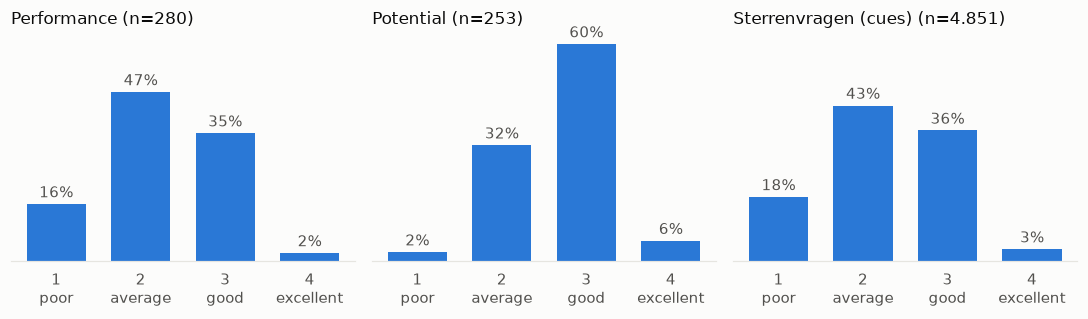

In [13]:
panels = [
    ("Performance", reports["performance"]),
    ("Potential", reports["potential"]),
    ("Sterrenvragen (cues)", ratings["rating"]),
]
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, (title, values) in zip(axes, panels):
    share = values.value_counts(normalize=True).reindex([1, 2, 3, 4], fill_value=0) * 100
    bars = ax.bar(share.index, share.values, width=0.7, color=BLUE)
    ax.bar_label(bars, labels=[f"{value:.0f}%" for value in share], padding=2, color=INK_MUTED)
    ax.set_title(f"{title} (n={values.notna().sum():,})".replace(",", "."))
    ax.set_xticks([1, 2, 3, 4], ["1\npoor", "2\naverage", "3\ngood", "4\nexcellent"])
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
fig.tight_layout()
plt.show()

### 5.2 N/A en niet ingevuld per categorie

N/A betekent dat de scout iets niet kon beoordelen en is dus geen score. Deze ontbrekende waarden zijn waarschijnlijk niet willekeurig: een keeper die geen 1-tegen-1 krijgt, kan daarop geen score krijgen.

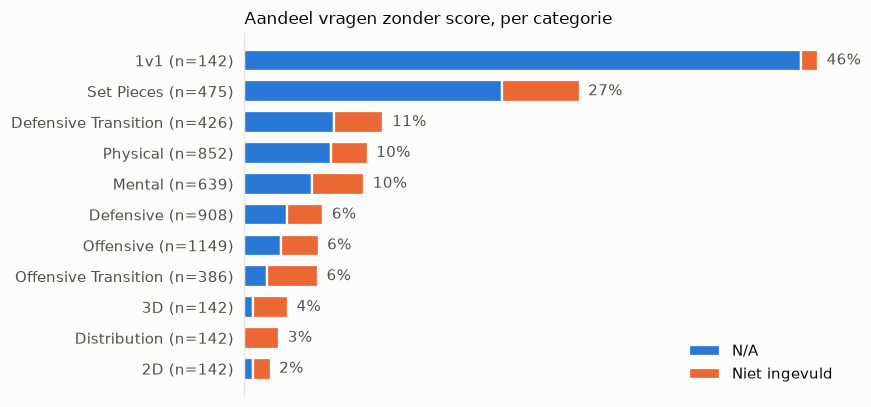

In [14]:
rating_categories = ratings.merge(questions[["question_id", "category_name"]], on="question_id")
missing_by_category = rating_categories.groupby("category_name").agg(
    na=("is_na", "mean"), not_filled=("is_missing", "mean"), n=("question_id", "size")
)
missing_by_category[["na", "not_filled"]] *= 100
missing_by_category["total"] = missing_by_category["na"] + missing_by_category["not_filled"]
missing_by_category = missing_by_category.sort_values("total")

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(missing_by_category))
ax.barh(y, missing_by_category["na"], height=0.7, color=BLUE, edgecolor=SURFACE, linewidth=1.5, label="N/A")
ax.barh(y, missing_by_category["not_filled"], left=missing_by_category["na"], height=0.7, color=ORANGE,
        edgecolor=SURFACE, linewidth=1.5, label="Niet ingevuld")
for position, value in zip(y, missing_by_category["total"]):
    ax.text(value + 0.7, position, f"{value:.0f}%", va="center", color=INK_MUTED)
ax.set_yticks(y, [f"{name} (n={row.n:.0f})" for name, row in missing_by_category.iterrows()])
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Aandeel vragen zonder score, per categorie")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 6. Cleaning

| Stap | Waarom |
|---|---|
| Lege en constante kolommen weg | Bevatten geen informatie |
| Datums en gehele getallen correct typeren | `performance` wordt anders `3.0` |
| `maturity` als geordende categorie | De volgorde is betekenisvol |
| Vlaggen toevoegen in plaats van rijen verwijderen | Zo blijven de keuzes omkeerbaar |
| Vraaginfo koppelen op `question_id` | `question_code` is niet uniek |

In [15]:
empty_cols = reports.columns[reports.isna().all()].tolist()
constant_cols = reports.columns[reports.notna().any() & (reports.nunique(dropna=False) == 1)].tolist()
print("Lege kolommen:", empty_cols)
print("Constante kolommen:", {col: reports[col].iloc[0] for col in constant_cols})

reports_clean = reports.drop(columns=empty_cols + constant_cols)

for col in ["created_at", "submitted_at", "match_date"]:
    reports_clean[col] = pd.to_datetime(reports_clean[col])
for col in ["performance", "potential", "duplicate_of", "home_score", "away_score", "lineup_minutes"]:
    reports_clean[col] = reports_clean[col].astype("Int64")
reports_clean["maturity"] = pd.Categorical(
    reports_clean["maturity"], categories=["Early Mature", "Normal", "Late Mature"], ordered=True
)

Lege kolommen: ['team_formation', 'opponent_formation', 'lineup_position']
Constante kolommen: {'season': '2025-2026', 'status': 'submitted', 'player_gender': 'M'}


In [16]:
straightlined = rating_stats.index[(rating_stats["count"] >= 2) & (rating_stats["nunique"] == 1)]

reports_clean["share_rated"] = (reports_clean["n_rated"] / reports_clean["n_questions"]).round(3)
reports_clean["is_repeat"] = reports_clean["duplicate_of"].notna()
reports_clean["is_bulk_import"] = reports_clean["mode"] == "unknown"
reports_clean["is_straightlined"] = reports_clean["report_id"].isin(straightlined)
reports_clean["is_goalkeeper"] = reports_clean["questionnaire_position"] == "GK"
reports_clean["minutes_suspect"] = (
    (reports_clean["lineup_starter"] == 1) & (reports_clean["lineup_minutes"] == 0)
)
reports_clean["position_differs"] = (
    reports_clean["position_played"] != reports_clean["questionnaire_position"]
)

# Voorlopige selectie voor het model van de scout: oordeel aanwezig en genoeg cues
reports_clean["is_usable"] = (
    ~reports_clean["is_repeat"]
    & reports_clean["performance"].notna()
    & (reports_clean["share_rated"] >= MIN_SHARE_RATED)
)

flags = ["is_repeat", "is_bulk_import", "is_straightlined", "is_goalkeeper",
         "minutes_suspect", "position_differs", "is_usable"]
reports_clean[flags].sum().rename("rapporten").to_frame()

,rapporten
is_repeat,2
is_bulk_import,31
is_straightlined,13
is_goalkeeper,71
minutes_suspect,40
position_differs,4
is_usable,272


In [17]:
ratings_clean = ratings.merge(
    questions[["question_id", "questionnaire_position", "category_name", "question_text"]],
    on="question_id", how="left", validate="many_to_one",
)
ratings_clean["rating"] = ratings_clean["rating"].astype("Int64")
ratings_clean["answer_status"] = np.select(
    [ratings_clean["is_na"] == 1, ratings_clean["is_missing"] == 1], ["na", "missing"], default="rated"
)
ratings_clean = ratings_clean.drop(columns=["is_na", "is_missing"])

assert len(ratings_clean) == len(ratings)
ratings_clean.head()

,report_id,question_id,question_code,rating,questionnaire_position,category_name,question_text,answer_status
0,153,76,AFB1,3,LB,Offensive,The player was available as a passing option in the build up phase,rated
1,153,77,AFB2,2,LB,Offensive,The player was able to contribute to the team's offensive play with his passing,rated
2,153,78,AFB3,<NA>,LB,Offensive,"The player was able to dominate in offensive 1v1 duels (take ons, take on %)",na
3,153,79,AFB4,3,LB,Offensive,The player contributed actively with his runs (overlaps / underlaps),rated
4,153,80,AFB5,2,LB,Offensive,"The player was able to create chances with his crosses (late, early, etc.)",rated


## 7. Cues per categorie

Veldspelers krijgen 21 tot 25 vragen, wat te veel is voor een regressie per scout. De tutorial raadt aan om maximaal zeven cues te gebruiken (Brehmer & Brehmer, 1988). Als eerste voorstel nemen we daarom per rapport het gemiddelde per categorie: dat geeft **zeven cues voor veldspelers en vier voor keepers**.

Let op: "Offensive" bevat voor een centrale verdediger andere vragen dan voor een spits. N/A en niet-ingevulde vragen tellen niet mee in het gemiddelde.

In [18]:
FIELD_CUES = ["Offensive", "Defensive", "Offensive Transition", "Defensive Transition",
              "Set Pieces", "Physical", "Mental"]
GK_CUES = ["2D", "3D", "1v1", "Distribution"]

context_cols = ["report_id", "scout_id", "player_id", "match_id", "questionnaire_position",
                "is_goalkeeper", "mode", "performance", "potential"]
usable = reports_clean.loc[reports_clean["is_usable"], context_cols]

cue_scores = ratings_clean[ratings_clean["report_id"].isin(usable["report_id"])].assign(
    rating=lambda df: df["rating"].astype("Float64")
).pivot_table(index="report_id", columns="category_name", values="rating", aggfunc="mean")

cues = usable.merge(cue_scores[FIELD_CUES + GK_CUES].astype(float).round(3), on="report_id")
assert len(cues) == len(usable)
cues.head()

,report_id,scout_id,player_id,match_id,questionnaire_position,is_goalkeeper,mode,performance,potential,Offensive,Defensive,Offensive Transition,Defensive Transition,Set Pieces,Physical,Mental,2D,3D,1v1,Distribution
0,153,10,4996,22107,LB,False,unknown,2,3,2.600,2.667,2.0,2.0,2.0,2.25,1.667,NaN,NaN,NaN,NaN
1,167,14,3465,22107,CB,False,unknown,2,3,2.200,2.714,3.0,2.5,2.0,2.25,3.000,NaN,NaN,NaN,NaN
2,162,13,326,3385,CDM,False,unknown,3,3,3.000,2.800,3.0,3.0,NaN,2.50,3.000,NaN,NaN,NaN,NaN
3,165,19,6279,494,CM,False,unknown,3,3,2.800,3.000,3.0,3.0,2.0,2.50,2.667,NaN,NaN,NaN,NaN
4,154,10,6319,258,RB,False,unknown,2,2,2.167,2.000,2.0,1.0,2.0,1.75,2.000,NaN,NaN,NaN,NaN


### 7.1 Is er genoeg data per scout?

Dit is de belangrijkste tabel van dit notebook. In de tutorial krijgt elke scout 50 spelers op 4 cues, en zelfs dat noemen de auteurs relatief klein. Onderstaande aantallen bepalen dus of we per scout kunnen schatten of scouts moeten samennemen.

In [19]:
field = cues[~cues["is_goalkeeper"]]
keepers = cues[cues["is_goalkeeper"]]

scout_summary = pd.DataFrame({
    "bruikbaar": cues.groupby("scout_id").size(),
    "veldspelers": field.groupby("scout_id").size(),
    "veld_alle_7_cues": field.dropna(subset=FIELD_CUES).groupby("scout_id").size(),
    "keepers": keepers.groupby("scout_id").size(),
    "keeper_alle_4_cues": keepers.dropna(subset=GK_CUES).groupby("scout_id").size(),
    "posities": cues.groupby("scout_id")["questionnaire_position"].nunique(),
    "spelers": cues.groupby("scout_id")["player_id"].nunique(),
}).fillna(0).astype(int).sort_values("bruikbaar", ascending=False)
display(scout_summary)
print("Totaal:", scout_summary[["bruikbaar", "veldspelers", "veld_alle_7_cues", "keepers", "keeper_alle_4_cues"]].sum().to_dict())

,bruikbaar,veldspelers,veld_alle_7_cues,keepers,keeper_alle_4_cues,posities,spelers
scout_id,,,,,,,
22,42,0,0,42,28,1,16
19,35,35,17,0,0,9,33
30,34,34,33,0,0,9,24
15,29,29,21,0,0,8,21
23,24,24,19,0,0,8,24
14,21,20,14,1,1,7,20
16,20,20,18,0,0,9,15
21,18,1,1,17,5,2,10
20,17,17,16,0,0,9,14


Totaal: {'bruikbaar': 272, 'veldspelers': 204, 'veld_alle_7_cues': 162, 'keepers': 68, 'keeper_alle_4_cues': 36}


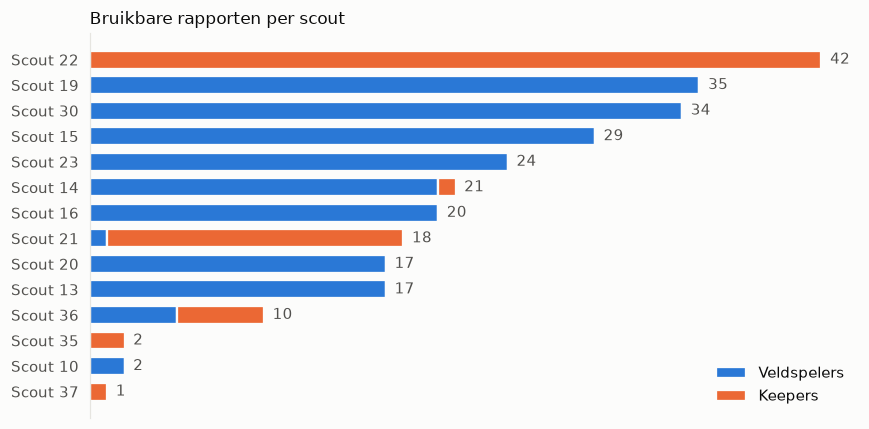

In [20]:
plot_data = scout_summary.sort_values("bruikbaar")
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(plot_data))
ax.barh(y, plot_data["veldspelers"], height=0.7, color=BLUE, edgecolor=SURFACE, linewidth=1.5, label="Veldspelers")
ax.barh(y, plot_data["keepers"], left=plot_data["veldspelers"], height=0.7, color=ORANGE,
        edgecolor=SURFACE, linewidth=1.5, label="Keepers")
for position, value in zip(y, plot_data["bruikbaar"]):
    ax.text(value + 0.5, position, str(value), va="center", color=INK_MUTED)
ax.set_yticks(y, [f"Scout {scout_id}" for scout_id in plot_data.index])
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Bruikbare rapporten per scout")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### 7.2 Verschillen tussen scouts

Gemiddeld oordeel per scout, voor scouts met minstens tien bruikbare rapporten. Grote verschillen wijzen op strengere of mildere scouts, maar kunnen ook komen doordat scouts andere spelers of competities bekijken.

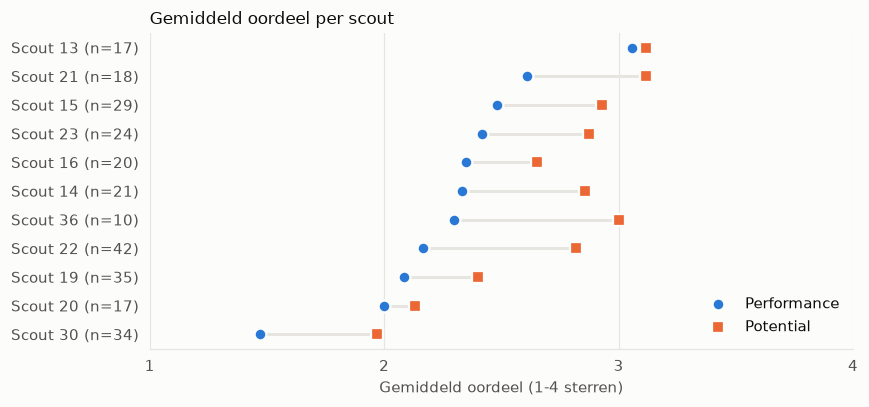

In [21]:
scout_means = cues.groupby("scout_id").agg(
    n=("report_id", "size"),
    performance=("performance", "mean"),
    potential=("potential", "mean"),
)
scout_means = scout_means[scout_means["n"] >= 10].astype(float).sort_values("performance")

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(scout_means))
ax.grid(axis="x")
ax.hlines(y, scout_means["performance"], scout_means["potential"], color=GRID, linewidth=2, zorder=1)
ax.scatter(scout_means["performance"], y, s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.5,
           label="Performance", zorder=2)
ax.scatter(scout_means["potential"], y, s=60, marker="s", color=ORANGE, edgecolor=SURFACE, linewidth=1.5,
           label="Potential", zorder=2)
ax.set_yticks(y, [f"Scout {scout_id} (n={row.n:.0f})" for scout_id, row in scout_means.iterrows()])
ax.set_xlim(1, 4)
ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel("Gemiddeld oordeel (1-4 sterren)")
ax.spines["left"].set_visible(False)
ax.set_title("Gemiddeld oordeel per scout")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 8. Wegschrijven

De bestanden in `data/clean/` bevatten geen namen of geboortedatums, maar blijven wel herleidbaar via de id's, ploegen en wedstrijden. Behandel ze dus nog steeds als persoonsgegevens.

In [22]:
CLEAN_DIR.mkdir(exist_ok=True)
outputs = {"reports_clean.csv": reports_clean, "ratings_clean.csv": ratings_clean, "cues_per_category.csv": cues}
for file_name, df in outputs.items():
    df.to_csv(CLEAN_DIR / file_name, index=False, encoding="utf-8-sig")
    print(f"{file_name}: {df.shape}")

reports_clean.csv: (284, 54)
ratings_clean.csv: (5403, 8)
cues_per_category.csv: (272, 20)


## 9. Open keuzes

Te bespreken bij de volgende versie:

1. **Criterium $Y_e$:** de data bevat geen objectieve prestatiemaat. Zonder criterium kunnen we alleen de kant van de scout schatten (gewichten en $R_s$), niet $r_a$, $R_e$, $r_m$, $G$ en $C$. Komt er nog een criterium, bijvoorbeeld speelminuten, marktwaarde of latere selectie?
2. **Niveau van de analyse:** per scout, of gepoold met een multilevel-model? Dat hangt af van de tabel in 7.1. Rapporten over dezelfde speler zijn bovendien niet onafhankelijk.
3. **Cues:** gemiddelde per categorie gebruiken, of iets anders? Kunnen vragen met dezelfde categorie over posities heen vergeleken worden?
4. **Keepers:** apart analyseren? Ze hebben andere cues en worden vooral door twee scouts beoordeeld.
5. **N/A:** rapporten met een ontbrekende cue weglaten of imputeren? Vooral Set Pieces en 1v1 hebben hier veel last van.
6. **Herhaalde rapporten:** nu telt het rapport uit `duplicate_of` als origineel. De herhalingen komen uit de bulkimport, dus het is niet zeker welk rapport echt eerst geschreven is.
7. **Bulkimport:** deze rapporten behouden of apart houden? Hun modus en timing zijn onbekend.
8. **Straightlining:** rapporten met overal dezelfde score behouden of niet? Een opvallend hoge consistentie kan hierdoor kunstmatig zijn.
9. **Zelfde bron voor cues en oordeel:** de scout vult beide in hetzelfde formulier in. Dat kan $R_s$ opdrijven, anders dan in de tutorial, waar cues vooraf vastliggen.